# Import packages & Load functions and data

In [1]:
import gzip

import math
import pysam
import glob, os
import subprocess
from collections import Counter
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

In [57]:
def load_vcf( PATH_vcf, isGzip=True ):
    skiplines = 0 
    if isGzip == True: 
        open_func = gzip.open 
    else:
        open_func = open
    with open_func(PATH_vcf, 'rt') as vcf:
        for line in vcf:
            if line[:2] == '##':
                skiplines += 1
            else:
                break 
    vcf = pd.read_csv(PATH_vcf, sep='\t', skiprows=skiplines)
    return vcf

def label_pathogenic_variants( str_clnsig ):
    if 'pathogenic' in str_clnsig.lower():
        return True 
    return False

def collect_flagstat_results(flagstat_results, DIR_flagstat_out, config):
    for PATH_flagstat in glob.glob(f'{DIR_flagstat_out}/*.flagstat.out'):
        with open(PATH_flagstat, 'r') as f:
            barcode = os.path.basename(PATH_flagstat.split('.')[0])
                
            for idx, line in enumerate(f.readlines()):
                if idx==0:
                    QC_passed_reads = int(line.strip().split(' ')[0])
                    QC_failed_reads = int(line.strip().split(' ')[2])
                elif idx==1:
                    QC_passed_primary_reads = int(line.strip().split(' ')[0])
                    QC_failed_primary_reads = int(line.strip().split(' ')[2])
                elif idx==2:
                    QC_passed_secondary_reads = int(line.strip().split(' ')[0])
                    QC_failed_secondary_reads = int(line.strip().split(' ')[2])
                elif idx==3:
                    QC_passed_supplementary_reads = int(line.strip().split(' ')[0])
                    QC_failed_supplementary_reads = int(line.strip().split(' ')[2])
                elif idx==6:
                    QC_passed_mapped_reads = int(line.strip().split(' ')[0])
                    QC_failed_mapped_reads = int(line.strip().split(' ')[2])
                elif idx==7:
                    QC_passed_mapped_primary_reads = int(line.strip().split(' ')[0])
                    QC_failed_mapped_primary_reads = int(line.strip().split(' ')[2])

            flagstat_results.append( [barcode, config, QC_passed_reads, QC_failed_reads, 
                                    QC_passed_primary_reads, QC_failed_primary_reads, 
                                    QC_passed_secondary_reads, QC_failed_secondary_reads,
                                    QC_passed_supplementary_reads, QC_failed_supplementary_reads, 
                                    QC_passed_mapped_reads, QC_failed_mapped_reads,
                                    QC_passed_mapped_primary_reads, QC_failed_mapped_primary_reads,
                                    ] )

## bcftools results

In [23]:
DIR_data = f'/home/18parkky/data/aml/paper'

In [ ]:
# NGS
NGS_vcf = load_vcf(f'{DIR_data}/bcftools/NGS.bcftools_merged.vcf.gz')
NGS_vcf = NGS_vcf[(NGS_vcf['ALT']!='.')].copy()                 # Limit analysis to SNV
NGS_vcf.columns = ['CHROM'] + list(NGS_vcf.columns)[1:]

In [ ]:
# ONT
ONT_vcf = load_vcf(f'{DIR_data}/bcftools/ONT.bcftools_merged.vcf.gz')
ONT_vcf = ONT_vcf[(ONT_vcf['ALT']!='.')].copy()                 # Limit analysis to SNV
ONT_vcf.columns = ['CHROM'] + list(ONT_vcf.columns)[1:]

In [11]:
palette_config = { 'FAST' : 'seagreen', 'HAC' : 'dodgerblue', 'SUP' : 'indianred', 'fast' : 'seagreen', 'hac' : 'dodgerblue', 'sup' : 'indianred' }

# Figure 2a

In [ ]:
# (a) Number of variants called by bcftools per sample (n = 54) with the fast, high-accuracy (HAC), and super-accuracy (SUP) basecalling models. Violins show the per-sample distribution; inner boxes indicate the interquartile range and dashed red lines the median for each model.

In [8]:
bcftools_variant_counts = list()
for config, ONT_vcf_config in ONT_vcf.groupby('config'):
    for SampleID, ONT_vcf_config_SampleID in ONT_vcf_config.groupby('SampleID'):
        bcftools_variant_counts.append( [config, SampleID, 
        ONT_vcf_config_SampleID[(ONT_vcf_config_SampleID['QUAL']>=30) & (ONT_vcf_config_SampleID['ALT']!='.')].shape[0]] )

bcftools_variant_counts = pd.DataFrame(bcftools_variant_counts, columns=['config', 'SampleID', 'num_variants'])

In [9]:
for config, edf in bcftools_variant_counts.groupby('config'):
    print(config, int(np.mean(edf['num_variants'])))

fast 25778
hac 10729
sup 9331


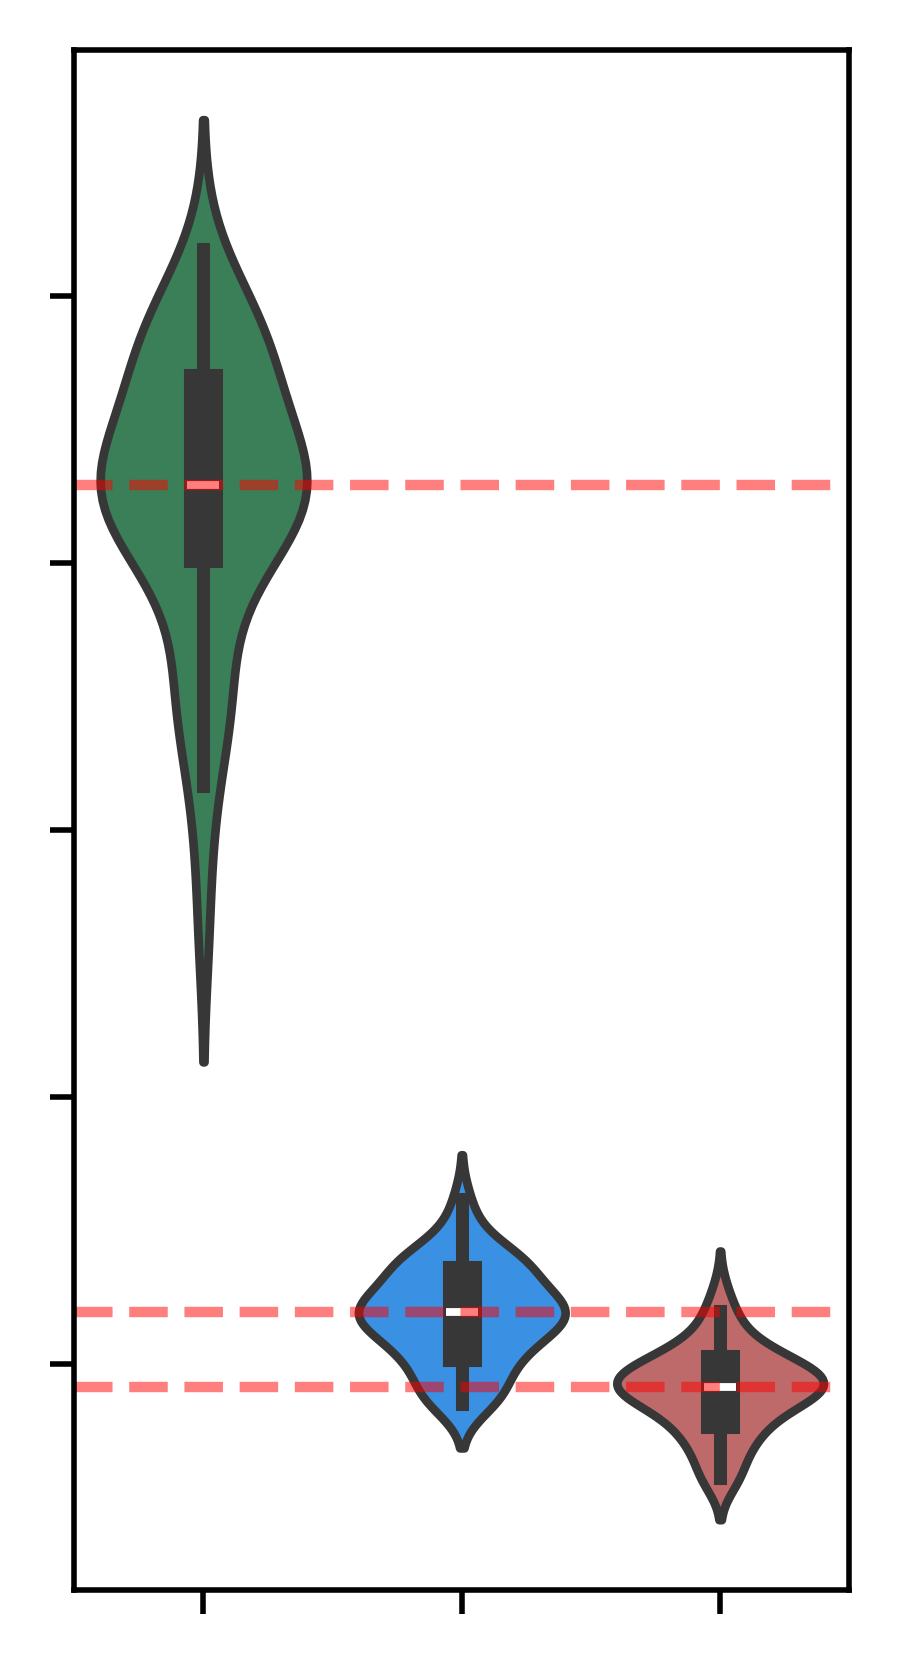

In [19]:
plt.figure(figsize=(2, 4), dpi=500)
ax = sns.violinplot(data=bcftools_variant_counts[(bcftools_variant_counts['SampleID']!='barcode25')], 
                    x='config', y='num_variants', color='gray', hue='config', palette=palette_config)
# ax.set_xlabel('Dorado basecalling model');
# ax.set_ylabel('Variants called by bcftools');
# ax.set_xticklabels(['FAST', 'HAC', 'SUP']);

ax.set_xlabel('');
ax.set_ylabel('');
ax.set_xticklabels([]);
ax.set_yticklabels([]);

for dorado_config, edf in bcftools_variant_counts[(bcftools_variant_counts['SampleID']!='barcode25')].groupby('config'):
    a = np.median(edf['num_variants'])
    # print(dorado_config, round(a, 1))
    ax.axhline(a , ls='--', alpha=0.5, color='red' );

# Figure 2b

In [21]:
NGS_vcf['Identifier'] = [ f'{tup.CHROM}:{tup.POS}:{tup.REF}>{tup.ALT}:{tup.barcode}' for tup in NGS_vcf.itertuples() ]
ONT_vcf['Identifier'] = [ f'{tup.CHROM}:{tup.POS}:{tup.REF}>{tup.ALT}:{tup.SampleID}' for tup in ONT_vcf.itertuples() ]

In [ ]:
# samtools depth -a -b ~/barcode14.bed -@ 24 ~/barcode14.rg.bam -o ~/barcode14.tsv
NGS_samtools_depth = list()

for PATH_samtools_depth in glob.glob(f'{DIR_data}/samtools_depth/barcode*.tsv'):
    NGS_samtools_depth_e = pd.read_csv(PATH_samtools_depth, sep='\t', header=None)
    NGS_samtools_depth_e.columns = ['chrom', 'pos', 'cov']
    NGS_samtools_depth_e['SampleID'] = os.path.basename(PATH_samtools_depth).split('.')[0]
    NGS_samtools_depth.append( NGS_samtools_depth_e )

NGS_samtools_depth = pd.concat(NGS_samtools_depth)
NGS_samtools_depth.reset_index(inplace=True, drop=True)

In [26]:
key = ['CHROM', 'POS', 'SampleID']

ngs_cov = (
    NGS_samtools_depth
    .rename(columns={'chrom': 'CHROM', 'pos': 'POS'})
    .set_index(key)['cov']
)

ONT_vcf['NGS_cov'] = ngs_cov.reindex(
    pd.MultiIndex.from_frame(ONT_vcf[key]), fill_value=0
).to_numpy()

In [27]:
ONT_vcf['NGS_confirmed'] = ONT_vcf['Identifier'].isin(NGS_vcf['Identifier'])

ONT_vcf_NGS_covered = (
    ONT_vcf
    .assign(str_GT=ONT_vcf['VALUES'].str.split(':', n=1).str[0])
    .query("NGS_cov >= 50 and str_GT != '0/0'")
)

concordance_results = (
    ONT_vcf_NGS_covered
    .drop_duplicates(['config', 'SampleID', 'Identifier'])
    .groupby(['config', 'SampleID'], observed=True)['NGS_confirmed']
    .agg(variants='size', NGS_confirmed_variants='sum')
    .reset_index()
    .assign(percentage=lambda d: 100 * d['NGS_confirmed_variants'] / d['variants'])
)

/tmp/ipykernel_1234516/2841211463.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['FAST', 'HAC', 'SUP']);


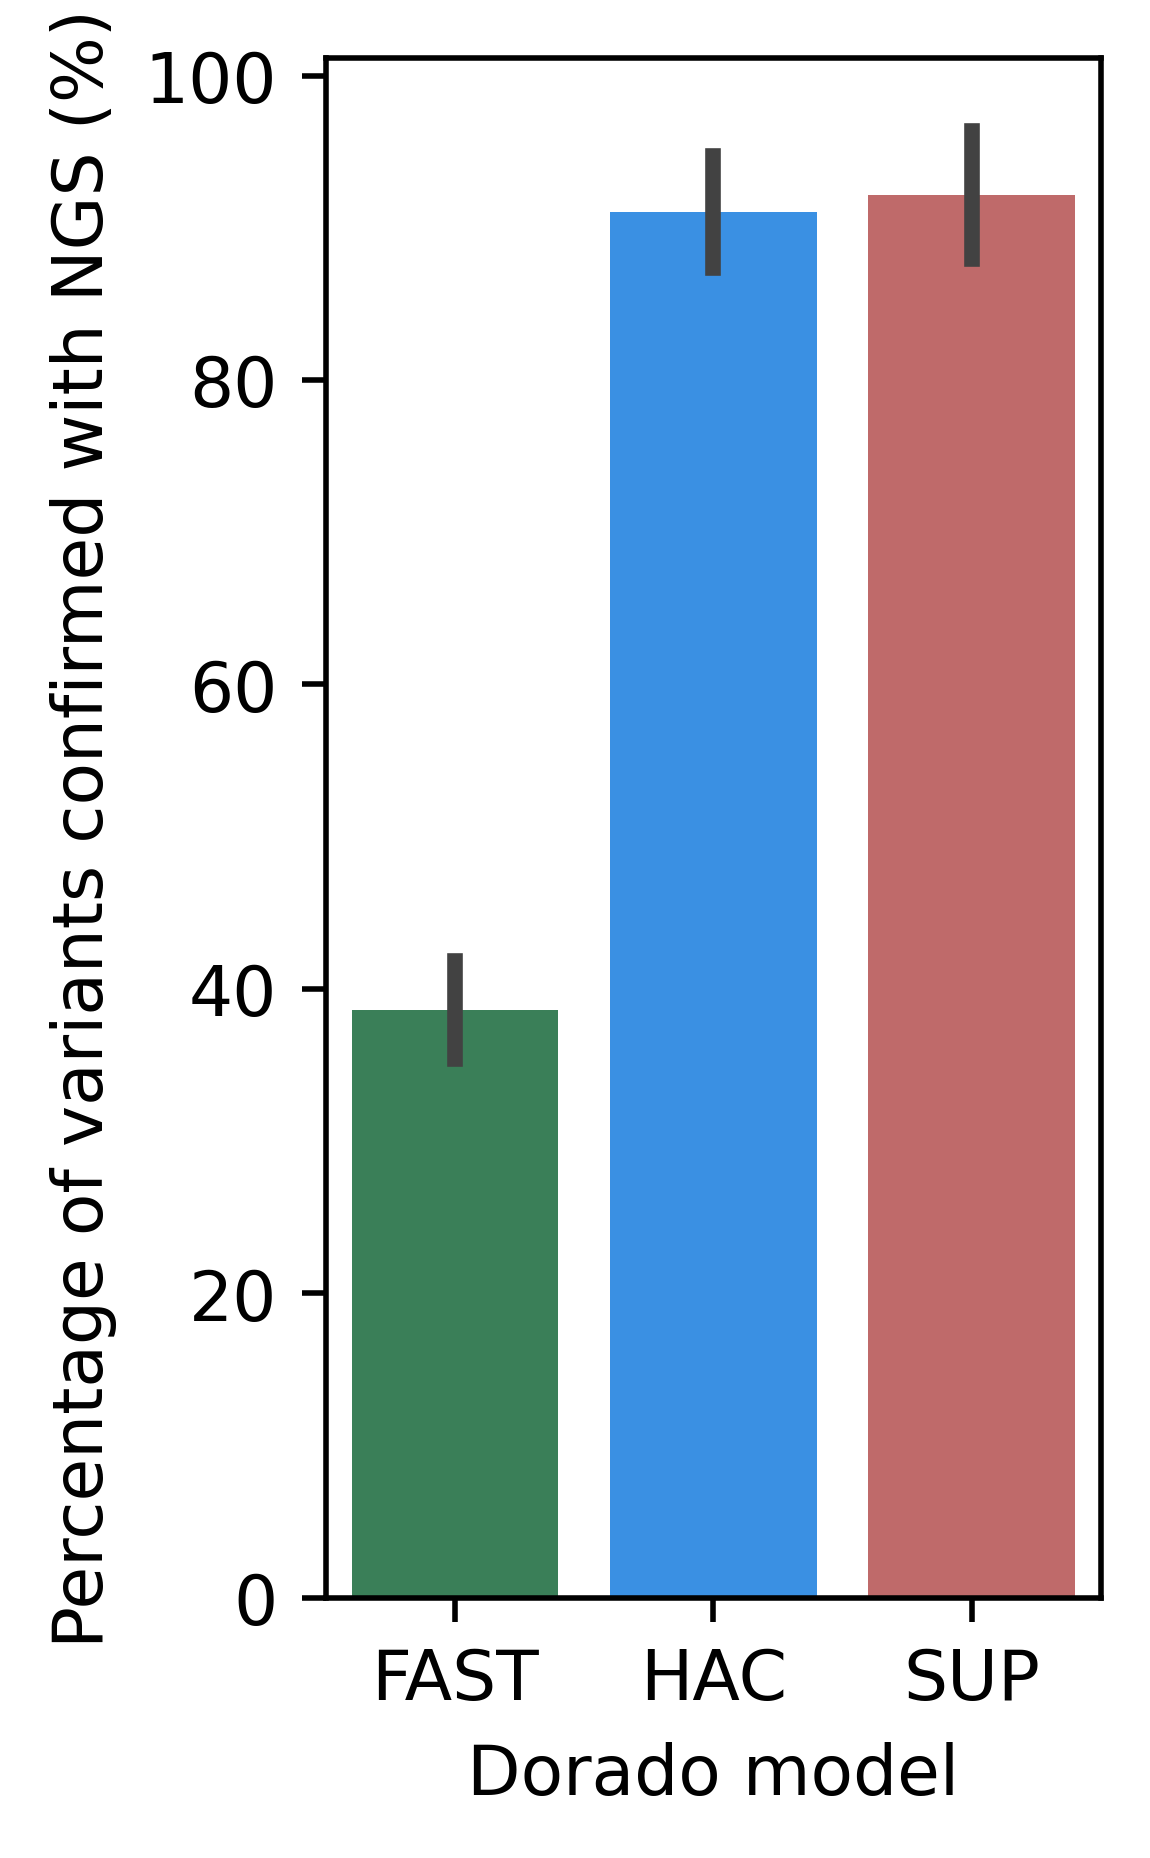

In [30]:
plt.figure(figsize=(2, 4), dpi=500);
ax = sns.barplot(data=concordance_results, x='config', y='percentage', errorbar='sd', color='grey', hue='config', palette=palette_config)
# ax.bar_label(container=ax.containers[0], fmt='%.2f');
# ax.bar_label(container=ax.containers[1], fmt='%.2f');
# ax.bar_label(container=ax.containers[2], fmt='%.2f');

ax.set_xlabel('Dorado model');
ax.set_ylabel('Percentage of variants confirmed with NGS (%)');
ax.set_xticklabels(['FAST', 'HAC', 'SUP']);

# Figure 2c (left)

In [ ]:
PATH_ONT_total_variants_clnsig_updated = f'{DIR_data}/final_vcfs/AML_ONT_annotated_variants_total.clnsig_updated.tsv.gz'
ONT_variants = pd.read_csv(PATH_ONT_total_variants_clnsig_updated, sep='\t',)

ONT_variants.shape[0]

/tmp/ipykernel_1234516/3858596685.py:5: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  ONT_variants = pd.read_csv(PATH_ONT_total_variants_clnsig_updated, sep='\t',)


1016689

In [44]:
ONT_variants_clinvar = ONT_variants[~(ONT_variants['CLNSIG'].isin( ['Not provided', 'NotAvailable'] ))].copy()
ONT_variants_clinvar['Identifier_SampleID'] = [ f'{tup.SampleID}_{tup.Identifier}' for tup in ONT_variants_clinvar.itertuples() ]
ONT_variants_clinvar['CLNSIG'] = ONT_variants_clinvar['CLNSIG'].fillna('NotAvailable')
ONT_variants_clinvar['is_pathogenic'] = ONT_variants_clinvar['CLNSIG'].apply( label_pathogenic_variants )
ONT_variants_clinvar = ONT_variants_clinvar[(ONT_variants_clinvar['SampleID']!='barcode53')].copy()


In [49]:
ONT_variants_clinvar_f_patho = ONT_variants_clinvar[(ONT_variants_clinvar['config']=='fast') & (ONT_variants_clinvar['is_pathogenic']==True)].copy()
ONT_variants_clinvar_h_patho = ONT_variants_clinvar[(ONT_variants_clinvar['config']=='hac') & (ONT_variants_clinvar['is_pathogenic']==True)].copy()
ONT_variants_clinvar_s_patho = ONT_variants_clinvar[(ONT_variants_clinvar['config']=='sup') & (ONT_variants_clinvar['is_pathogenic']==True)].copy()

In [50]:
ONT_variants_clinvar_patho_merged = pd.concat([ONT_variants_clinvar_f_patho, ONT_variants_clinvar_h_patho, ONT_variants_clinvar_s_patho])
ONT_variants_clinvar_patho_merged.reset_index(inplace=True, drop=True)
ONT_variants_clinvar_patho_merged['config'] = ONT_variants_clinvar_patho_merged['config'].apply(str.upper)

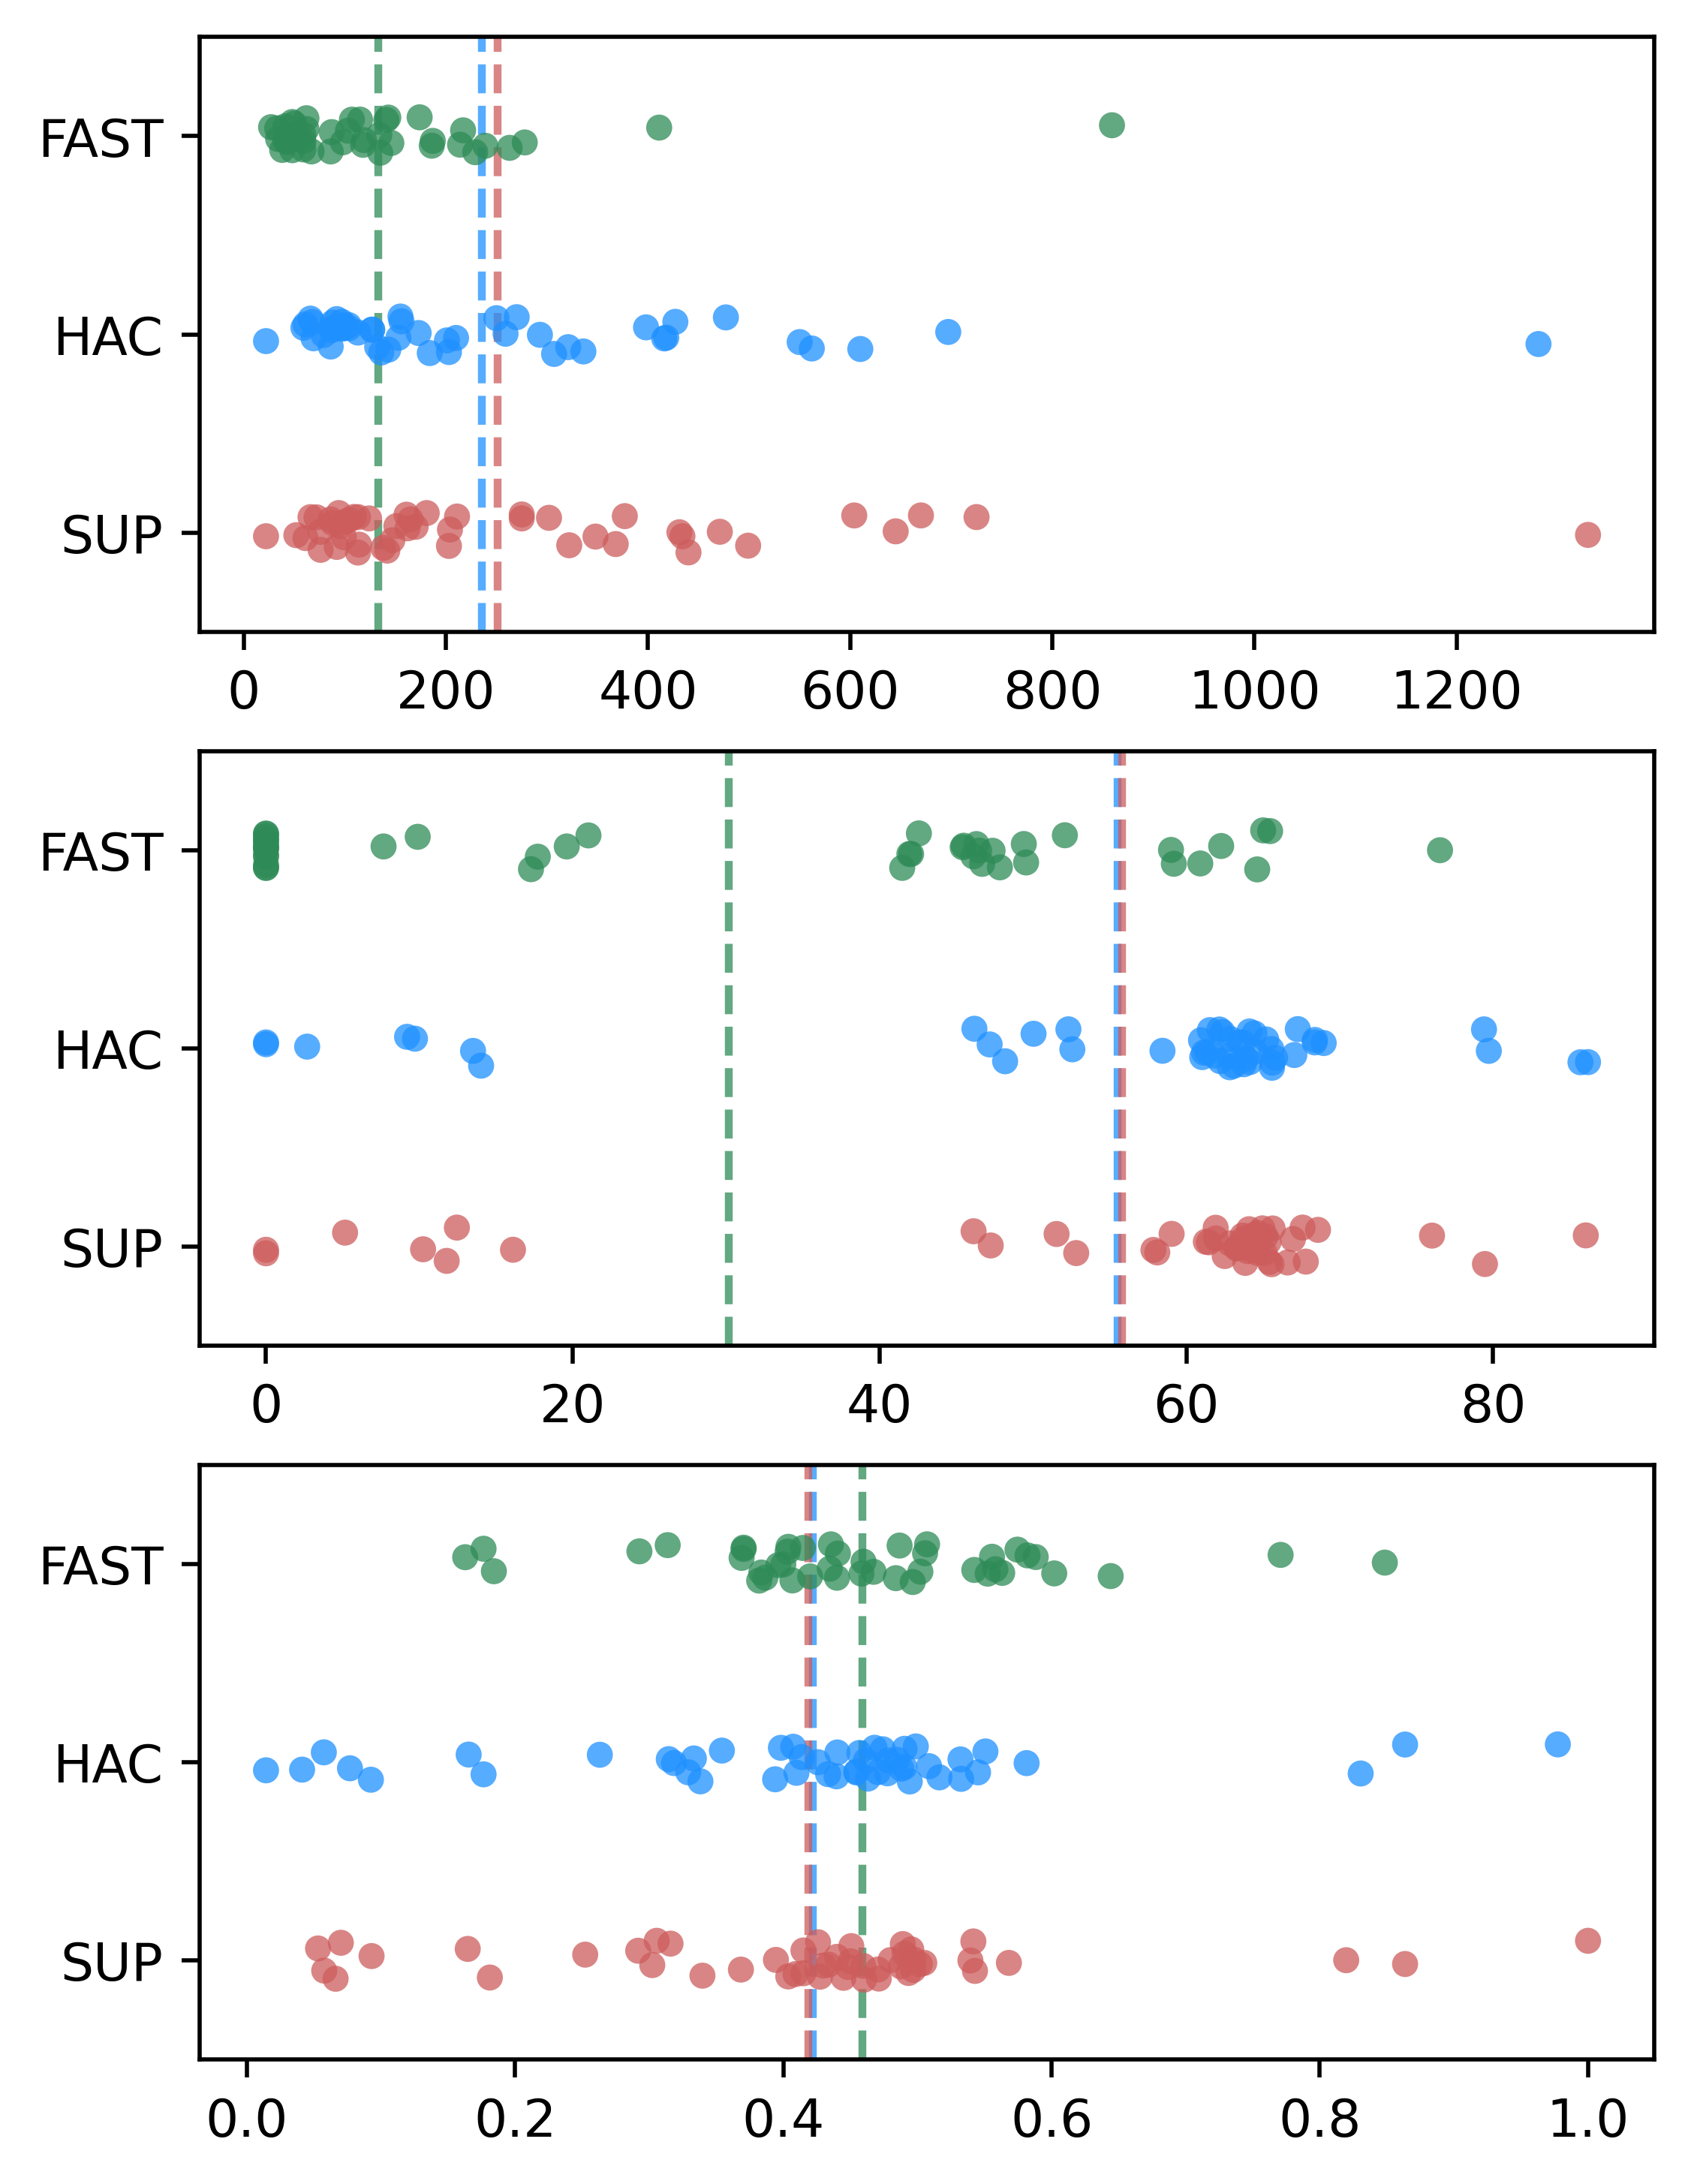

In [51]:
fig, axes = plt.subplots( 3, 1, figsize=(5, 7), sharey=True, dpi=500);

ax = sns.stripplot(data=ONT_variants_clinvar_patho_merged, y='config', x='DP', ax=axes[0], hue='config', palette=palette_config, alpha=0.75,);
ax = sns.stripplot(data=ONT_variants_clinvar_patho_merged, y='config', x='QUAL', ax=axes[1], hue='config', palette=palette_config, alpha=0.75,);
ax = sns.stripplot(data=ONT_variants_clinvar_patho_merged, y='config', x='AF', ax=axes[2], hue='config', palette=palette_config, alpha=0.75,);

for config, edf in ONT_variants_clinvar_patho_merged.groupby('config'):
    axes[0].axvline( np.mean(edf['DP']), color=palette_config[config], ls='--', alpha=0.75, )
    axes[1].axvline( np.mean(edf['QUAL']), color=palette_config[config], ls='--', alpha=0.75, )
    axes[2].axvline( np.mean(edf['AF']), color=palette_config[config], ls='--', alpha=0.75, )

axes[0].set_xlabel('');
axes[1].set_xlabel('');
axes[2].set_xlabel('');

axes[0].set_ylabel('');
axes[1].set_ylabel('');
axes[2].set_ylabel('');

# Figure 2c (right)

In [ ]:
''' 
# fast
list_run1_fast_mm2_PATH_BAM = glob.glob(f'{DIR_run1_fast_mm2_out}/*.bam')
for PATH_BAM in list_run1_fast_mm2_PATH_BAM:
    barcode = os.path.basename(PATH_BAM).split('.')[0]
    PATH_flagstat_out = f'{DIR_fast_flagstat_out}/{barcode}.flagstat.out'
    if os.path.exists(PATH_flagstat_out)==True: continue
    cmd = f'samtools flagstat {PATH_BAM} -@ {threads} > {PATH_flagstat_out}'
    subprocess.call(cmd, shell=True)

# hac
list_run1_hac_mm2_PATH_BAM = glob.glob(f'{DIR_run1_hac_mm2_out}/*.bam')
for PATH_BAM in list_run1_fast_mm2_PATH_BAM:
    barcode = os.path.basename(PATH_BAM).split('.')[0]
    PATH_flagstat_out = f'{DIR_run1_hac_mm2_out}/{barcode}.flagstat.out'
    if os.path.exists(PATH_flagstat_out)==True: continue
    cmd = f'samtools flagstat {PATH_BAM} -@ {threads} > {DIR_hac_flagstat_out}/{barcode}.flagstat.out'
    subprocess.call(cmd, shell=True)

# sup
list_run1_sup_mm2_PATH_BAM = glob.glob(f'{DIR_run1_sup_mm2_out}/*.bam')
for PATH_BAM in list_run1_fast_mm2_PATH_BAM:
    barcode = os.path.basename(PATH_BAM).split('.')[0]
    PATH_flagstat_out = f'{DIR_run1_sup_mm2_out}/{barcode}.flagstat.out'
    if os.path.exists(PATH_flagstat_out)==True: continue
    cmd = f'samtools flagstat {PATH_BAM} -@ {threads} > {DIR_sup_flagstat_out}/{barcode}.flagstat.out'
    subprocess.call(cmd, shell=True)
'''

In [55]:
flagstat_results = list()
collect_flagstat_results(flagstat_results, f'{DIR_data}/flagstat/fast', 'fast')
collect_flagstat_results(flagstat_results, f'{DIR_data}/flagstat/hac', 'hac')
collect_flagstat_results(flagstat_results, f'{DIR_data}/flagstat/sup', 'sup')

flagstat_results = pd.DataFrame(flagstat_results, columns=['SampleID', 'config', 
                                                           'passed', 'failed',      # passed = QC-passed reads, failed = QC-failed reads
                                                           'passed_p', 'failed_p',  # passed_p = QC-passed primary reads, failed_p = QC-failed primary reads
                                                           'passed_s', 'failed_s',  # passed_s = QC-passed secondary reads, failed_s = QC-failed secondary reads
                                                           'passed_sup', 'failed_sup', # passed_sup = QC-passed supplementary reads, failed_sup = QC-failed supplementary reads
                                                           'passed_mapped', 'failed_mapped',  
                                                           'passed_mapped_p', 'failed_mapped_p'])
flagstat_results = flagstat_results[(flagstat_results['SampleID']!='barcode25')].copy()
flagstat_results['mapping_rate'] = 100 * flagstat_results['passed_mapped'] / flagstat_results['passed']
flagstat_results['primary_mapping_rate'] = 100 * flagstat_results['passed_mapped_p'] / flagstat_results['passed_p']
flagstat_results['supplementary_mapping_rate'] = 100 * flagstat_results['passed_mapped_p'] / flagstat_results['passed_p']
flagstat_results['config'] = flagstat_results['config'].apply(str.upper)

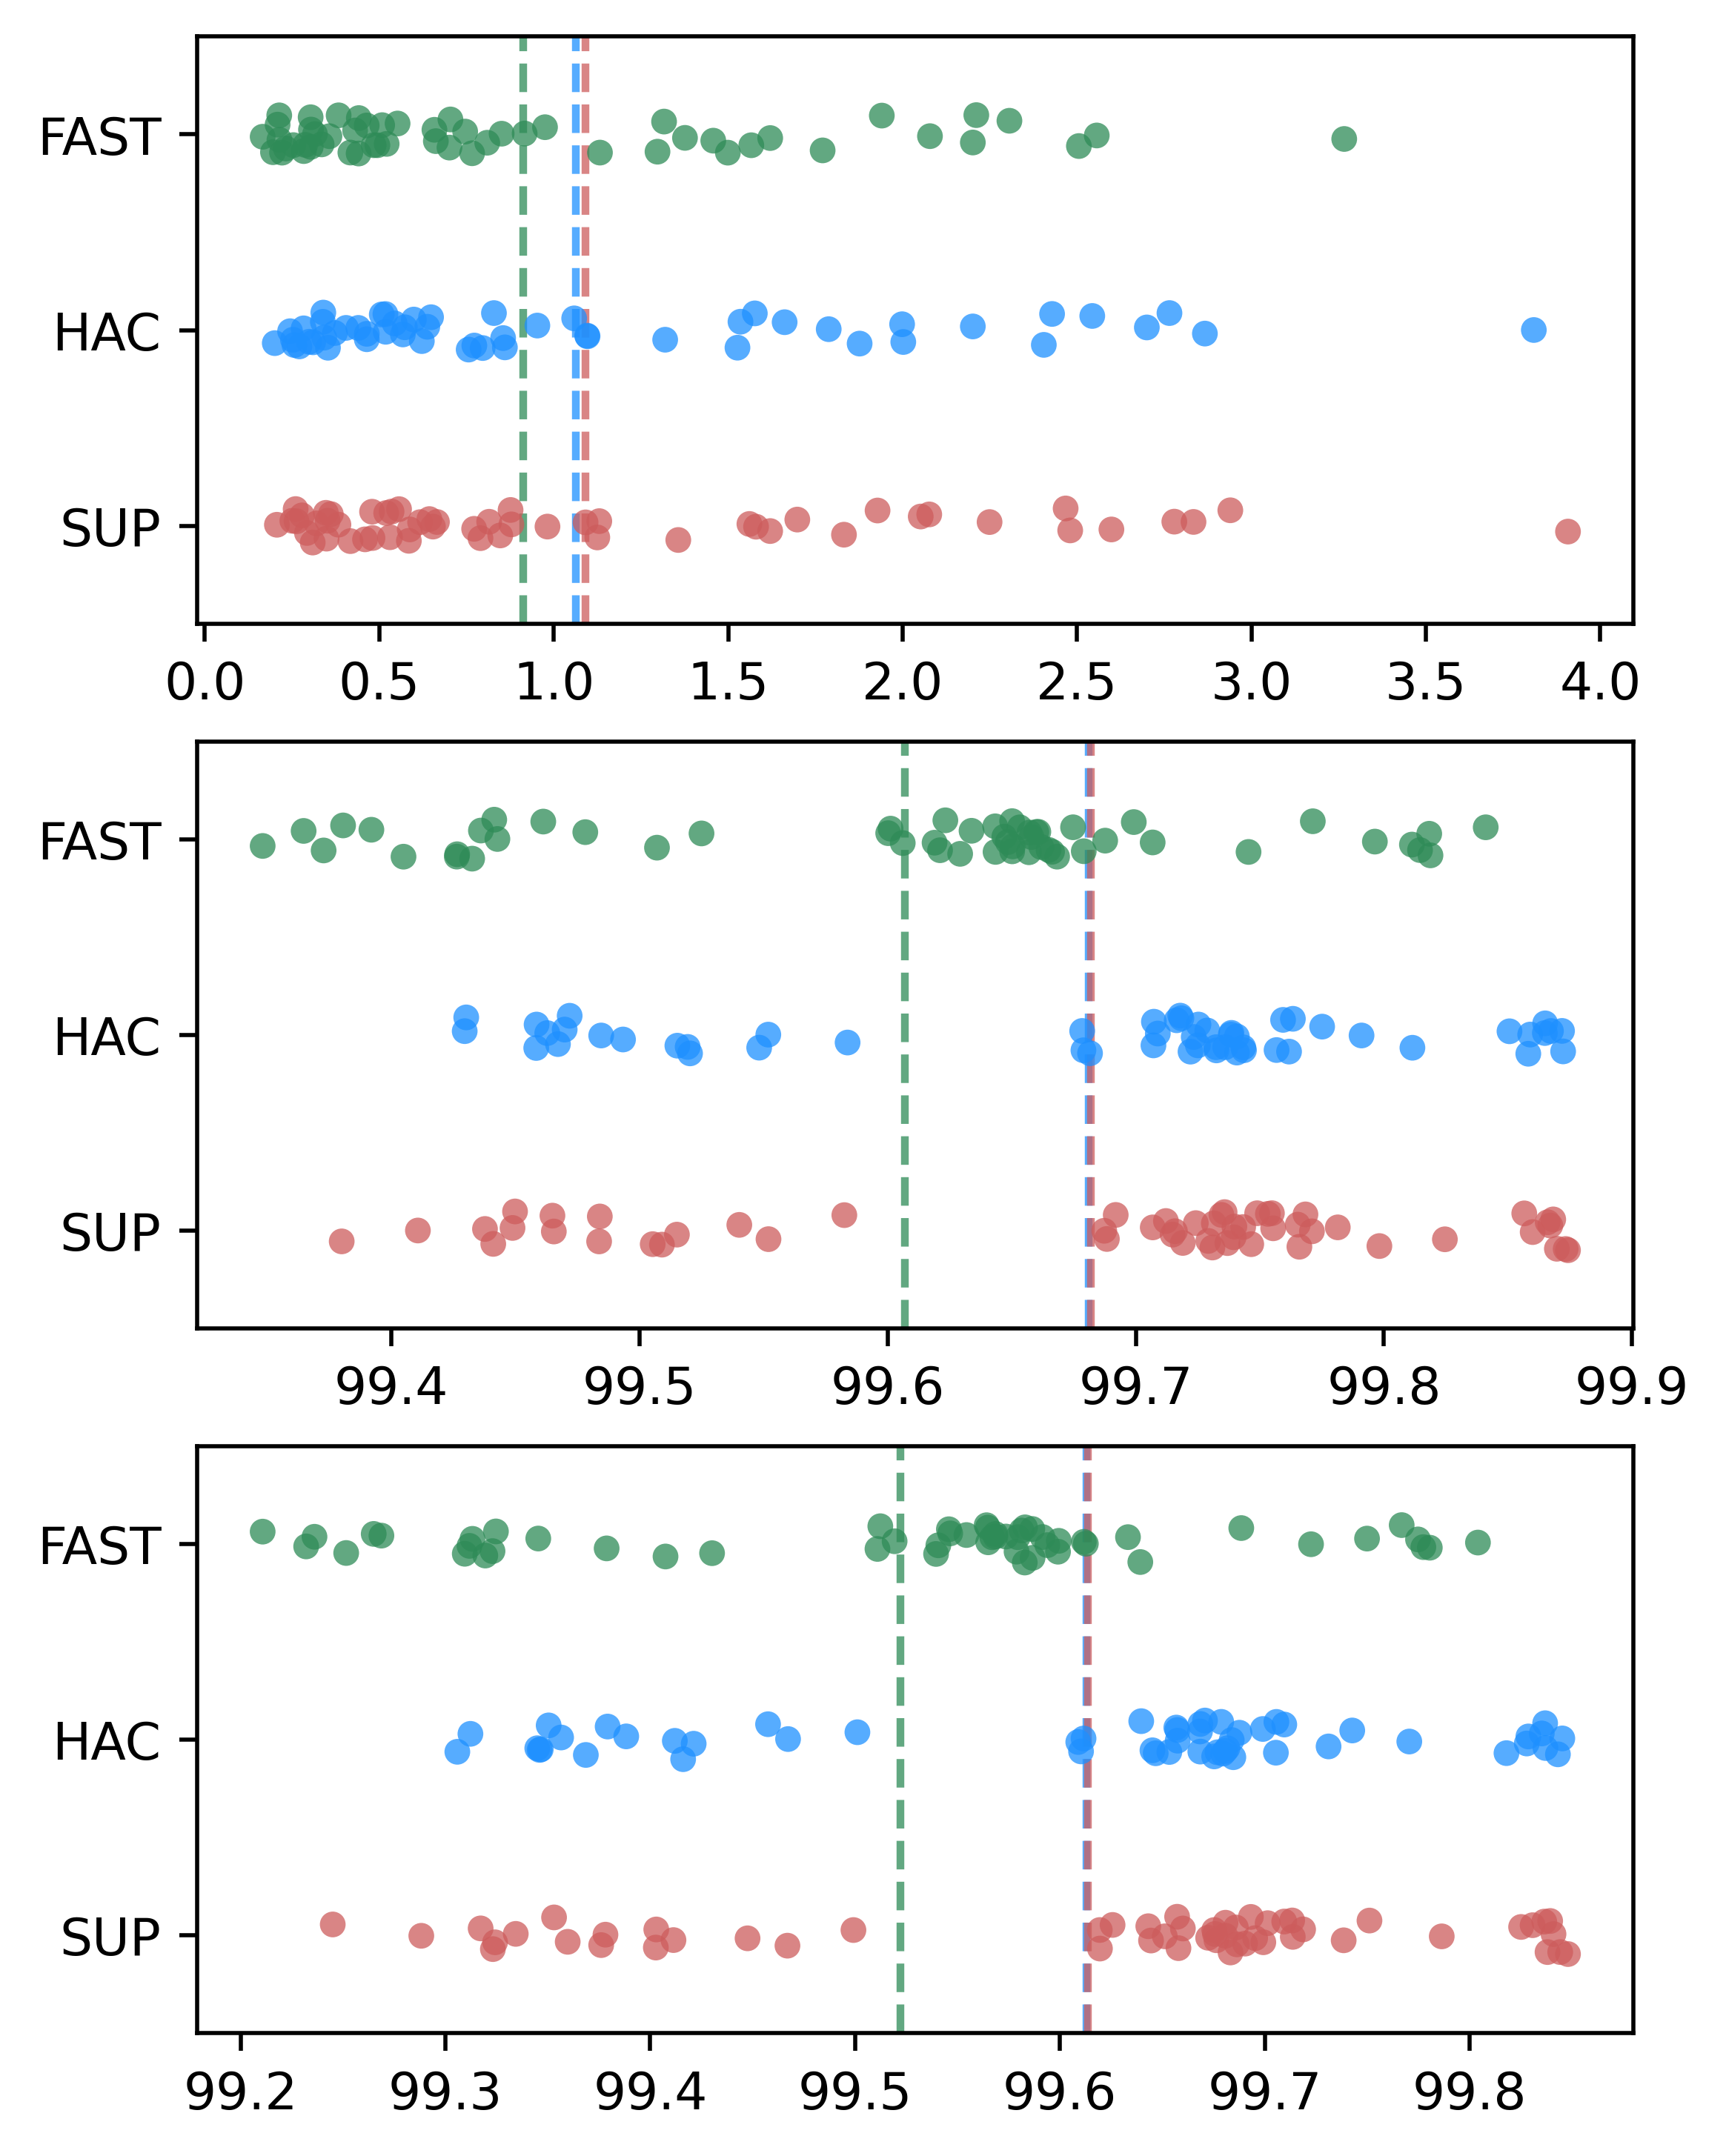

In [58]:
fig, axes = plt.subplots( 3, 1, figsize=(5, 7), sharey=True, dpi=500);

ax = sns.stripplot(data=flagstat_results, y='config', x='passed_p', ax=axes[0], hue='config', palette=palette_config, alpha=0.75,);
ax = sns.stripplot(data=flagstat_results, y='config', x='mapping_rate', ax=axes[1], hue='config', palette=palette_config, alpha=0.75,);
ax = sns.stripplot(data=flagstat_results, y='config', x='primary_mapping_rate', ax=axes[2], hue='config', palette=palette_config, alpha=0.75,);

for config, edf in flagstat_results.groupby('config'):
    axes[0].axvline( np.mean(edf['passed_p']), color=palette_config[config], ls='--', alpha=0.75, )
    axes[1].axvline( np.mean(edf['mapping_rate']), color=palette_config[config], ls='--', alpha=0.75, )
    axes[2].axvline( np.mean(edf['primary_mapping_rate']), color=palette_config[config], ls='--', alpha=0.75, )

axes[0].set_xlabel('');
axes[1].set_xlabel('');
axes[2].set_xlabel('');
axes[0].xaxis.get_offset_text().set_visible(False)

axes[0].set_ylabel('');
axes[1].set_ylabel('');
axes[2].set_ylabel('');

# axes[2].set_xlim([95, 100]);